<H1>Ising</H1> 
A place to fool around with the Ising model
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 19-Nov-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
    <tr> 
        <td> 20-Nov-26 </td>
        <td> CBL </td> 
        <td> Made into class </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
References: <br> 

<H2> Notes </H2>
The 2D ising model Hamiltonian looks like:

$H = -J \sum_{(i,j)} s_i s_j - h \sum_i S_i $

with $s_i = \pm 1$

We can have a matrix of n by n that serves to hold the information for the individual spins. The transistion matrix
for evolving this ends up being quite large. We choose to have a local matrix instead. 

$\Delta E = 2s_{ij}(J \sum_{neighbors} s_{kl} + h)

Then using the metropolis algorithm we accept the flip with probability 

$ P_{accept} = min(1,e^{-{{{\Delta E}}\over(k_B T)}})$

Proceedure for Metropolis algorithm: 
<ol>
    <li> Choose the lattice site (i,j) at random </li>
    <li> Calculate the energy change $\Delta E$ if its spin were flipped </li>
    <li> If $\Delta E \leq 0$, accept the flip</li>
    <li> If $\Delta E \gt 0$, accept it with probablity $e^{-{{{\Delta E}}\over(k_B T)}}$ </li>
    <li> Repeat</li>
</ol>

This algorighm generates configurations sampled from the Boltzman distribution: 

$P(S) \propto e^{-{{H(S)}\over{k_B T}}}$

we can use the sensor to modify the local field $h_{ij}$ later. 

<ul>
    <li> Start with at 32 x 32 lattice for simulation</li>
    <li> Start with random configuration and watch the domains emerge</li>
    <li> Later start with ordered lattice and watch disorder arise</li>
    <li> add in local perterbations</li>
</ul>

As a benchmark test, ${{k_B T_c}\over J} \approx 2.269$ Below this value large ordered domains become favorable. 

In [1]:
# My imports
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import scipy.constants   as konst

<H1> Measure the magnetization</H1>
Quantative check that the average magnetization per spin is:

$m = {1\over {N^2}}\sum_{i,j} s_{ij}$

The T used in the above cells is really a scaled dimensionaless value. 

$T^* = {{k_B * T_{physical}}\over{J}}$ 

Lets invert that:

In [40]:
class Ising2D:
    def __init__(self):
        """
        Initialize the model. 
        """
        self.N = 64       # lattice size
        self.J = 1.0      # Spin-Spin coupling strength
        self.T = 1.5      # Temperature in dimensionless units. 
        self.h = 0.0      # Magnetic field, or coupling energy in Joules = -uBs_i

        self.rng = np.random.default_rng(42)
        self.Reset()

    def Reset(self):
        # Random initial spins of: +1 or -1
        self.spins = rng.choice([-1,1], size=(N,N))

    def PlotInitial(self):
        plt.figure(figsize=(6,6))
        plt.imshow(self.spins, cmap="coolwarm", vmin=-1, interpolation="nearest")
        plt.title("Initial random configuration")
        # if in python alone, we need a plt.show()

    def energy_per_spin(self):
        neighbors = (
            np.roll(self.spins, -1, axis=0)
            + np.roll(self.spins, -1, axis=1)
        )
        E = -self.J * np.sum(self.spins*neighbors)
        E -= self.h * np.sum(self.spins)
        return E/self.spins.size

    def metropolis_sweep(self):
        """
        metropolis sweep
        Each sweep attempts N^2 spin flips. The four nearest neighbors determine the energy change. 
        """
        N, M = self.spins.shape
        for _ in range(N * M):
            i = self.rng.integers(N)
            j = self.rng.integers(M)

            # periodic boundry conditions
            neighbors = (
                self.spins[(i + 1) % N, j] 
                + self.spins[(i-1)%N, j]
                + self.spins[i, (j+1)%M]
                + self.spins[i, (j-1)%M]
            )
            dE = 2 * self.spins[i,j] * (self.J * neighbors + self.h)
            if dE < 0 or self.rng.random() < np.exp(-dE/self.T) :
                self.spins[i,j] *= -1

    def Magnetization(self):
        """
        @return the magnetization over the full lattice. 
        """
        magnetization = np.mean(self.spins)
        print(f"Magnetization: {magnetization: .4f}")
        return magnetization

    def Temperature(self):
        """
        @return the physical temperature in K
        J is not in joules, assume that the coupling is about 1meV
        """
        T_physical = self.J*1.0e-3 * konst.eV *self.T/konst.k
        print(f"Actual temperature: {T_physical:.2f} K")
        return T_physical
        
    def CurrentState(self):
        """
        Print out the Magnetization and current energy per spin a this time step. 
        """
        energy = self.energy_per_spin()
        print(f"Magnetization: {np.mean(spins):.4f}")
        print(f"Energy per spin: {energy:.4f}")

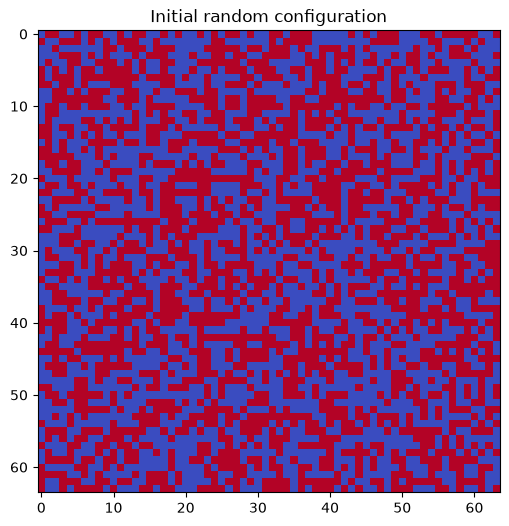

In [41]:
# Initialize and plot initial state
i2d = Ising2D()
i2d.PlotInitial()

Magnetization: -0.4326
Energy per spin: 0.0186
Magnetization: -0.4326
Energy per spin: -1.5020
Magnetization: -0.4326
Energy per spin: -1.7666
Magnetization: -0.4326
Energy per spin: -1.8428
Magnetization: -0.4326
Energy per spin: -1.9463


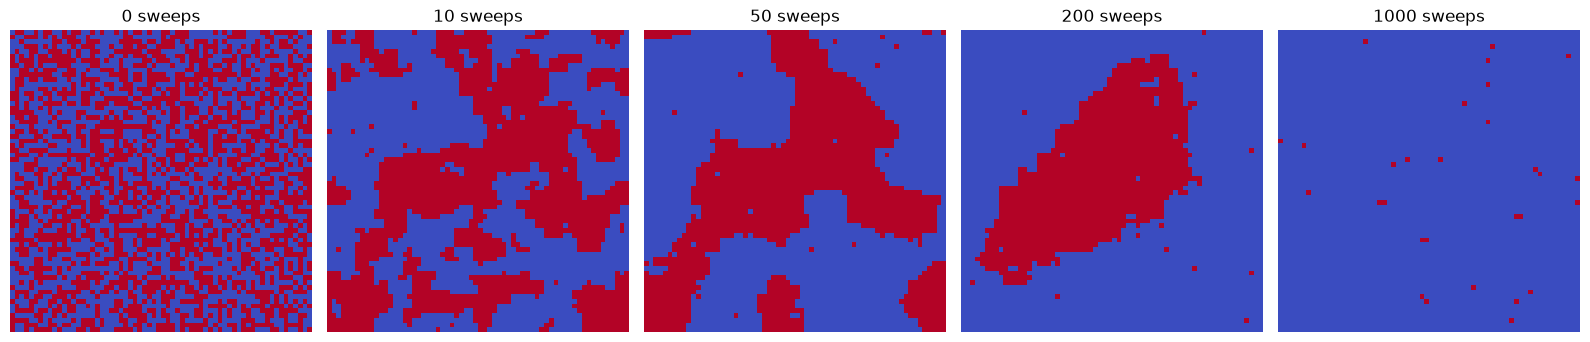

In [42]:
# Now evolve the system 
# Observe after 0, 10 50 200 1000 iterations

checkpoints = [0, 10, 50, 200, 1000]
#checkpoints = [0, 100, 500, 2000, 10000]

fig, axes = plt.subplots(1, len(checkpoints),figsize=(16,4))

completed = 0

for ax, target in zip(axes, checkpoints):
    for _ in range(target-completed):
         i2d.metropolis_sweep()
    completed = target

    ax.imshow( i2d.spins, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(f"{target} sweeps")
    ax.axis("off")

    # per checkpoint
    i2d.CurrentState()
plt.tight_layout()
#plt.show()
                 